<img src="../Imagenes/logo-final-ap.png" width="85" align="left"/>

# <span style="color:#bd232b">Aprendizaje Profundo</span>

[GitHub de Aprendizaje Profundo](https://github.com/AprendizajeProfundo)
## <span style="color:#174ea6">Cuaderno 101 · Procesos de decisión de Markov y fundamentos del aprendizaje por refuerzo</span>
### Curso de inteligencia artificial avanzada · Ecopetrol · Hydro-Lab

**Autores:** Alvaro Montenegro · Daniel Montenegro · Pilar Montenegro  
**Docente:** Alvaro Montenegro,  [ammontenegrod@gmail.com](mailto:ammontenegrod@gmail.com),  
**Institución:** Universidad de los Andes - Ecopetrol  
**Edición docente:** 108 · Octubre de 2026  
**Licencia del contenido y código originales de esta edición:** MIT (véase sección final).

> **Idea rectora.** Antes de entrenar una red neuronal, debemos entender qué significa tomar una decisión, qué información tiene el agente y qué consecuencias futuras genera su acción.

**Fuentes de esta edición:** consolidación y reelaboración de `01_ar_Aprendizaje_Reforzado_Intro.ipynb`, `02_ar_Agente_simple.ipynb`, `03_ar_Bandido_Multi_brazo .ipynb` y `06_r_OpenAI_Gym_Frozen_Lake.ipynb`. Los cuadernos originales permanecen intactos.

**Edición 101A — ampliación con el oficinista y el bandido multibrazo.**

## Guía de navegación y resultados de aprendizaje

**Tiempo de clase estimado: ~75–90 minutos con las ampliaciones**; las secciones de profundización y los ejercicios adicionales se destinan al estudio posterior.

1. El ratón, el queso y las decisiones secuenciales.
2. Agente, ambiente, episodio y recompensa.
3. Cadenas de Markov y procesos de recompensa.
4. MDP: estados, acciones, transición, recompensa y descuento.
5. Políticas, retornos, funciones de valor y Bellman.
6. Experimento reproducible: evaluar políticas y mejorar una política.
7. Exploración–explotación y observabilidad.
8. Del ratón a Hydro-Lab.
9. Ejercicios, controles de comprensión y referencias.

Al terminar, el participante podrá **formular un MDP finito**, calcular y verificar numéricamente valores, interpretar Bellman, comparar políticas y reconocer qué aspectos de Hydro-Lab no se describen completamente mediante la observación disponible.

**Dependencias:** Python 3.10+, `numpy` y `matplotlib`. No se necesita GPU, conexión a internet ni acceso al simulador para ejecutar este cuaderno.

# <span style="color:#174ea6">1. El ratón, el queso y la descarga eléctrica</span>


La situación introductoria procede del cuaderno original de Aprendizaje Profundo: un ratón robótico recorre un laberinto. Algunas decisiones lo acercan al queso; otras lo exponen a descargas eléctricas. **Una buena acción no es necesariamente la que produce la mayor recompensa inmediata:** puede convenir atravesar un paso incómodo para alcanzar una recompensa posterior.

<img src="../Imagenes/cheese-mouse-maze.jpg" width="360"/>

*Figura original de la colección de Aprendizaje Profundo; el cuaderno fuente indica que está basada en material de Depositphotos. Conservar su atribución y verificar las condiciones de uso de la imagen en la distribución pública.*

**Pregunta inicial:** si el camino corto al queso tiene riesgo de descarga y el camino largo es seguro, ¿qué información necesitamos para elegir?

Definiremos un laberinto pequeño y completamente especificado para que todas las afirmaciones matemáticas puedan verificarse.

### 1.1 Agente y ambiente: un ciclo de interacción

En el instante $t$, el agente observa información $O_t$, elige una acción $A_t$, y el ambiente devuelve una recompensa $R_{t+1}$ y una nueva observación $O_{t+1}$. Si la observación coincide con el estado verdadero, escribiremos $S_t$.

<img src="../Imagenes/environment.png" width="650"/>

*Figura: interacción agente–ambiente, procedente de `01_ar_Aprendizaje_Reforzado_Intro.ipynb`.*

**Vocabulario mínimo:**

- **Estado:** descripción suficiente del sistema para predecir su evolución condicionada a una acción.
- **Acción:** decisión que modifica, o puede modificar, el estado siguiente.
- **Recompensa:** señal numérica de desempeño; no es lo mismo que un objetivo físico ni que una restricción de seguridad.
- **Episodio:** secuencia de interacción con una condición de finalización.
- **Política:** regla, posiblemente probabilística, que determina acciones.

La **recompensa acumulada descontada** —no una recompensa aislada— será nuestra referencia para valorar una política.


# <span style="color:#174ea6">2. De un proceso estocástico a una cadena de Markov</span>

Un proceso estocástico es una sucesión de variables aleatorias $(S_0,S_1,\ldots)$. La **propiedad de Markov** afirma que el futuro inmediato, condicionado al presente, no depende de la historia anterior:

$$
P(S_{t+1}=s'\mid S_t=s,S_{t-1},\ldots,S_0)
=P(S_{t+1}=s'\mid S_t=s).
$$

En una cadena de Markov finita, la matriz de transición $P$ cumple

$$
P_{ij}=P(S_{t+1}=j\mid S_t=i),\qquad P_{ij}\ge 0,\qquad\sum_j P_{ij}=1.
$$

**Importante:** la propiedad de Markov depende de la definición del estado. Una observación que omite variables dinámicas importantes puede no ser markoviana.

### 2.1 Un ejemplo verificable: tres estados del ratón

Por ahora **no hay acciones**. El ratón cambia entre `descanso`, `comida` y `descarga` de acuerdo con una matriz de transición fija. Este es un ejemplo didáctico, no una medición experimental.

Filas = estado actual; columnas = siguiente estado
[[0.6 0.3 0.1]
 [0.4 0.5 0.1]
 [0.5 0.1 0.4]]


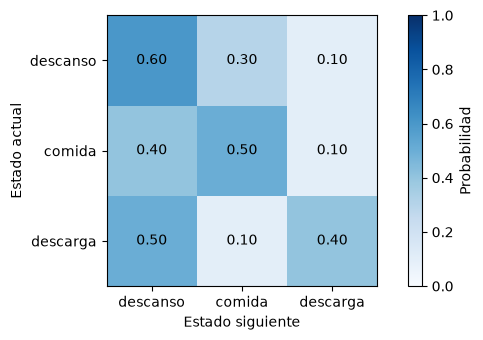

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
SEED = 2026
rng = np.random.default_rng(SEED)

estados = ["descanso", "comida", "descarga"]
P = np.array([[0.60, 0.30, 0.10],
              [0.40, 0.50, 0.10],
              [0.50, 0.10, 0.40]])
assert np.all(P >= 0) and np.allclose(P.sum(axis=1), 1)
print("Filas = estado actual; columnas = siguiente estado")
print(P)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
im = ax.imshow(P, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3), estados)
ax.set_yticks(range(3), estados)
ax.set_xlabel("Estado siguiente")
ax.set_ylabel("Estado actual")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{P[i,j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Probabilidad")
plt.tight_layout(); plt.show()

### 2.2 Recompensas y retorno

Si a cada transición se asocia una recompensa, obtenemos un **proceso de recompensa de Markov**. Su retorno desde el instante $t$ es

$$
G_t=R_{t+1}+\gamma R_{t+2}+\gamma^2R_{t+3}+\cdots,
\qquad 0\le\gamma<1.
$$

Para episodios finitos, la suma termina al concluir el episodio. El factor $\gamma$ controla la importancia relativa del futuro; **no** equivale automáticamente a una tasa financiera de descuento.

La función de valor es una esperanza condicional:

$$
V(s)=\mathbb{E}[G_t\mid S_t=s].
$$

**Discusión:** dos recorridos pueden producir igual recompensa inmediata y retornos muy diferentes.

In [3]:
recompensas = np.array([0.0, 5.0, -4.0])
gamma = 0.90

def retorno_descuento(rews, gamma=0.90):
    return sum((gamma**t)*float(r) for t, r in enumerate(rews))

ruta_segura = [0, 0, 5]
ruta_arriesgada = [-4, 5]
print("Ruta segura:", round(retorno_descuento(ruta_segura, gamma), 3))
print("Ruta arriesgada:", round(retorno_descuento(ruta_arriesgada, gamma), 3))
assert retorno_descuento(ruta_segura) > retorno_descuento(ruta_arriesgada)

Ruta segura: 4.05
Ruta arriesgada: 0.5


## 2A. El oficinista: un ejemplo completo de proceso de recompensa de Markov

En este caso el agente es el oficinista y el ambiente está constituido por la oficina en donde trabaja y su casa. El oficinista puede estar en uno de cuatro estados: coffe, computer. chat y home.

La imagen ilustra una forma clásica de mostrar un proceso de Markov. Los círculos muestran los estados posibles del agente y las flechas en el grafo están etiquetados las probabilidad de pasar de un estado a otro. Por ejemplo, la probabilidad de pasar de cofffe a chat es 0.7. Puede imaginar que si el oficinista va por un café, lo mas probable es que termine entablando una conversación con algún compañero. Por fuerza de la costumbre llamaremos a nuestro oficinista Dilbert. El nombre proviene del personaje principal de la serie televisa Scott Adams.

### 2A.1 Probabilidades de transición


<img src="../Imagenes/oficinista_MP.png" width="740"/>



### 2A.2 Las mismas probabilidades, ahora con recompensas

Cada salida tiene ahora dos números:

- $p$: probabilidad de que ocurra.
- $r$: recompensa recibida si ocurre.

Por ejemplo, una de las salidas de `chat` ocurre con probabilidad $0.5$ y produce recompensa $-1$. Otra ocurre con probabilidad $0.3$ y produce recompensa $2$.

La diferencia es fundamental: **probabilidad** responde «¿con qué frecuencia?» y **recompensa** responde «¿qué gano o pierdo si ocurre?».

<img src="../Imagenes/oficinista_recompensa.png" width="740"/>



### 2A.3 Tabla completa de probabilidades y recompensas utilizadas

| Estado de origen | Salida | Probabilidad $p$ | Recompensa $r$ |
|---|---:|---:|---:|
| chat | 1 | 0.50 | -1 |
| chat | 2 | 0.30 | 2 |
| chat | 3 | 0.20 | 1 |
| coffee | 1 | 0.70 | 2 |
| coffee | 2 | 0.10 | 1 |
| coffee | 3 | 0.20 | 3 |
| home | 1 | 0.60 | 1 |
| home | 2 | 0.40 | 1 |
| computer | 1 | 0.50 | 5 |
| computer | 2 | 0.10 | -3 |
| computer | 3 | 0.20 | 1 |
| computer | 4 | 0.20 | 2 |

**Ejercicio a mano.** Desde `chat`, la recompensa esperada de **la próxima transición** es:

$$
\mathbb{E}[R_{t+1}\mid S_t=\mathrm{chat}]
=0.5(-1)+0.3(2)+0.2(1)=0.3.
$$

Repetimos el cálculo para cada estado:

$$
\begin{aligned}
\bar r(\mathrm{chat}) &= -1(0.5)+2(0.3)+1(0.2)=0.3,\\
\bar r(\mathrm{coffee}) &= 2(0.7)+1(0.1)+3(0.2)=2.1,\\
\bar r(\mathrm{home}) &= 1(0.6)+1(0.4)=1.0,\\
\bar r(\mathrm{computer}) &= 5(0.5)-3(0.1)+1(0.2)+2(0.2)=2.8.
\end{aligned}
$$

Matemáticamente, con los datos mostrados aquí se tienen  **recompensas inmediatas esperadas**. Para calcular la función de valor $V(s)$ del retorno descontado se necesita, además, conocer los destinos de cada transición y el factor de descuento $\gamma$. Esta distinción será importante cuando estudiemos Bellman.

In [17]:
import numpy as np
datos_oficinista = {
    "chat":     (np.array([.5, .3, .2]),      np.array([-1, 2, 1])),
    "coffee":   (np.array([.7, .1, .2]),      np.array([2, 1, 3])),
    "home":     (np.array([.6, .4]),          np.array([1, 1])),
    "computer": (np.array([.5, .1, .2, .2]),  np.array([5, -3, 1, 2]))
}
for estado, (p, r) in datos_oficinista.items():
    assert np.isclose(p.sum(), 1.0)
    print(f"{estado:9s}: recompensa inmediata esperada = {np.dot(p,r):.1f}")
assert np.allclose([np.dot(*v) for v in datos_oficinista.values()],
                   [.3, 2.1, 1.0, 2.8])


chat     : recompensa inmediata esperada = 0.3
coffee   : recompensa inmediata esperada = 2.1
home     : recompensa inmediata esperada = 1.0
computer : recompensa inmediata esperada = 2.8


### 2A.4 ¿Qué hemos aprendido?

Una cadena de Markov permite describir cómo cambia un sistema entre estados. Un proceso de recompensa de Markov añade ganancias o pérdidas a esos cambios. El siguiente paso, el **MDP**, incorpora algo nuevo: **acciones que el agente puede elegir** para influir en las transiciones.

El oficinista ilustra estados, probabilidades y recompensas. El ratón de las secciones siguientes ilustra además decisiones.

# <span style="color:#174ea6">3. Procesos de decisión de Markov (MDP)</span>


Un **MDP** finito se representa mediante la quíntupla

$$
\mathcal M=(\mathcal S,\mathcal A,P,R,\gamma),
$$

donde $\mathcal S$ es el espacio de estados, $\mathcal A$ el de acciones, $P(s'\mid s,a)$ la probabilidad de transición, $R(s,a,s')$ la recompensa esperada condicionada a la transición y $\gamma$ el descuento.

<img src="../Imagenes/MDP.png" width="740"/>

*Figura original de MDP con el ratón, tomada de `01_ar_Aprendizaje_Reforzado_Intro.ipynb`; conservar la atribución indicada allí.*

Una política estocástica es

$$
\pi(a\mid s)=P(A_t=a\mid S_t=s),\qquad \sum_a\pi(a\mid s)=1.
$$

En una política determinista, para cada estado una acción tiene probabilidad uno.

**Precisión:** en la literatura también se escribe $R(s,a)=\sum_{s'}P(s'\mid s,a)R(s,a,s')$. Indicaremos cuál convención emplea cada experimento.

### 3.1 Laboratorio: un ratón en un MDP finito

Construimos un entorno **nuevo y reducido**, inspirado en la historia original, para observar exactamente el efecto de las decisiones:

- `Inicio`: el ratón debe decidir entre un pasillo seguro y un atajo riesgoso.
- `Pasillo seguro`: conduce al queso con una transición adicional.
- `Atajo riesgoso`: puede llevar al queso o a una descarga terminal.
- `Queso` y `Descarga`: estados terminales.

La penalización de movimiento es `−0.2`, la llegada al queso produce `+10` y la descarga `−8`. El atajo llega al queso con probabilidad `0.70` y a la descarga con probabilidad `0.30`. **Son supuestos pedagógicos declarados, no datos de Hydro-Lab.**

In [10]:
S = ["Inicio", "Seguro", "Atajo", "Queso", "Descarga"]
A = ["seguro", "atajo"]
INICIO, SEGURO, ATAJO, QUESO, DESCARGA = range(5)
TERMINALES = {QUESO, DESCARGA}

# T[s][a] = lista de (probabilidad, estado siguiente, recompensa)
T = {
  INICIO: {0: [(1.0, SEGURO, -0.2)], 1: [(1.0, ATAJO, -0.2)]},
  SEGURO: {0: [(1.0, QUESO, 10.0)], 1: [(1.0, QUESO, 10.0)]},
  ATAJO: {0: [(0.7, QUESO, 10.0), (0.3, DESCARGA, -8.0)],
          1: [(0.7, QUESO, 10.0), (0.3, DESCARGA, -8.0)]},
  QUESO: {0: [(1.0, QUESO, 0.0)], 1: [(1.0, QUESO, 0.0)]},
  DESCARGA: {0: [(1.0, DESCARGA, 0.0)], 1: [(1.0, DESCARGA, 0.0)]},
}
for s in range(len(S)):
    for a in range(len(A)):
        assert np.isclose(sum(p for p, _, _ in T[s][a]), 1.0)
print("MDP validado:", len(S), "estados;", len(A), "acciones")

MDP validado: 5 estados; 2 acciones


### 3.2 Ejecutar episodios

Una simulación sirve para observar trayectorias y estimar valores. La definición de MDP, sin embargo, permite también calcular expectativas **exactamente** mediante ecuaciones lineales.

In [18]:
def ejecutar_episodio(politica, seed=0, max_pasos=20):
    gen = np.random.default_rng(seed)
    s, trayectoria = INICIO, []
    for _ in range(max_pasos):
        if s in TERMINALES:
            break
        a = int(gen.choice(len(A), p=politica[s]))
        transiciones = T[s][a]
        j = int(gen.choice(len(transiciones), p=[x[0] for x in transiciones]))
        _, siguiente, recompensa = transiciones[j]
        trayectoria.append((S[s], A[a], float(recompensa), S[siguiente]))
        s = siguiente
    return trayectoria, s in TERMINALES

# Política 1: elegir siempre el pasillo seguro desde Inicio.
pi_segura = np.array([[1., 0.]] * len(S))
# Política 2: elegir siempre el atajo desde Inicio.
pi_atajo = pi_segura.copy(); pi_atajo[INICIO] = [0., 1.]
# Política 3: alternar probabilísticamente.
pi_mixta = pi_segura.copy(); pi_mixta[INICIO] = [0.5, 0.5]

for nombre, pi in [("Segura", pi_segura), ("Atajo", pi_atajo), ("Mixta", pi_mixta)]:
    trayectoria, completo = ejecutar_episodio(pi, seed=12)
    print(nombre, "|", trayectoria, "| terminado:", completo)

Segura | [('Inicio', 'seguro', -0.2, 'Seguro'), ('Seguro', 'seguro', 10.0, 'Queso')] | terminado: True
Atajo | [('Inicio', 'atajo', -0.2, 'Atajo'), ('Atajo', 'seguro', 10.0, 'Queso')] | terminado: True
Mixta | [('Inicio', 'seguro', -0.2, 'Seguro'), ('Seguro', 'seguro', 10.0, 'Queso')] | terminado: True



# <span style="color:#174ea6">4. Funciones de valor y ecuaciones de Bellman</span>

La función de valor de una política $\pi$ es

$$
V^\pi(s)=\mathbb E_\pi[G_t\mid S_t=s].
$$

La función acción-valor es

$$
Q^\pi(s,a)=\mathbb E_\pi[G_t\mid S_t=s,A_t=a].
$$

La ecuación de **Bellman para evaluación de política** expresa una identidad de consistencia:

$$
V^\pi(s)=\sum_a\pi(a\mid s)\sum_{s'}P(s'\mid s,a)
\bigl[R(s,a,s')+\gamma V^\pi(s')\bigr].
$$

En estados terminales fijamos $V^\pi(s)=0$ para el retorno futuro *después* de terminar. La recompensa de entrada al terminal se contabiliza en la transición previa.

**Interpretación:** el valor de un estado es el promedio ponderado de recompensa inmediata más valor descontado del siguiente estado.

In [19]:
def modelo_inducido(politica):
    """Devuelve P_pi y r_pi bajo una política estocástica."""
    n = len(S)
    Ppi = np.zeros((n, n))
    rpi = np.zeros(n)
    for s in range(n):
        for a in range(len(A)):
            for p, siguiente, r in T[s][a]:
                Ppi[s, siguiente] += politica[s, a] * p
                rpi[s] += politica[s, a] * p * r
    return Ppi, rpi

def evaluar_politica(politica, descuento=0.9):
    Ppi, rpi = modelo_inducido(politica)
    # Estados terminales absorbentes con recompensa futura nula.
    V = np.linalg.solve(np.eye(len(S)) - descuento * Ppi, rpi)
    assert np.allclose(V, rpi + descuento * Ppi @ V)
    return V

for nombre, pi in [("Segura", pi_segura), ("Atajo", pi_atajo), ("Mixta", pi_mixta)]:
    v = evaluar_politica(pi)
    print(f"{nombre:7s} V(Inicio) = {v[INICIO]:7.3f}; valores = {v}")

Segura  V(Inicio) =   8.800; valores = [ 8.8 10.   4.6  0.   0. ]
Atajo   V(Inicio) =   3.940; valores = [ 3.94 10.    4.6   0.    0.  ]
Mixta   V(Inicio) =   6.370; valores = [ 6.37 10.    4.6   0.    0.  ]


### 4.1 Del valor de una política al valor óptimo

El principio de optimalidad reemplaza el promedio sobre acciones por una maximización:

$$
V^*(s)=\max_a\sum_{s'}P(s'\mid s,a)
\left[R(s,a,s')+\gamma V^*(s')\right].
$$

Una política codiciosa respecto a $V^*$ elige una acción que alcance el máximo. Esto no es aún **Q-learning**: aquí conocemos explícitamente el modelo de transiciones y recompensas. Q-learning, que veremos en el cuaderno 102, aprende valores a partir de experiencia sin necesitar esta tabla de probabilidades.

V*(Inicio): 8.8
Acción óptima desde Inicio: seguro


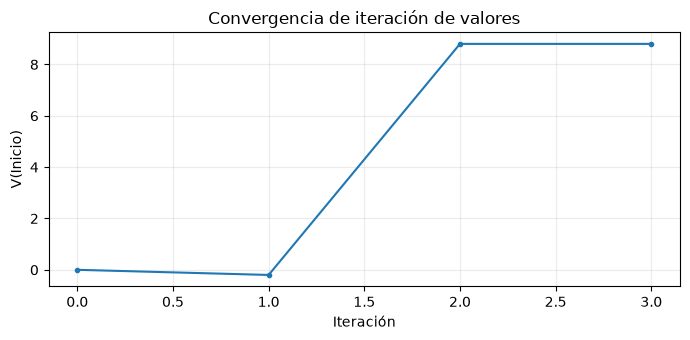

In [13]:
def iteracion_valores(descuento=0.9, tolerancia=1e-12, max_iter=10000):
    V = np.zeros(len(S))
    historia = [V.copy()]
    for it in range(max_iter):
        Q = np.zeros((len(S), len(A)))
        for s in range(len(S)):
            for a in range(len(A)):
                Q[s, a] = sum(p * (r + descuento * V[sp])
                              for p, sp, r in T[s][a])
        Vnuevo = Q.max(axis=1)
        historia.append(Vnuevo.copy())
        if np.max(np.abs(Vnuevo - V)) < tolerancia:
            V = Vnuevo
            break
        V = Vnuevo
    politica_optima = np.argmax(Q, axis=1)
    return V, politica_optima, np.array(historia)

Vopt, acciones_optimas, historia = iteracion_valores()
print("V*(Inicio):", round(Vopt[INICIO], 4))
print("Acción óptima desde Inicio:", A[acciones_optimas[INICIO]])
assert A[acciones_optimas[INICIO]] == "seguro"
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(historia[:, INICIO], marker="o", markersize=3)
ax.set(title="Convergencia de iteración de valores", xlabel="Iteración", ylabel="V(Inicio)")
ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

### 4.2 Validación por simulación Monte Carlo

Comparamos el valor exacto calculado con Bellman y la media de retornos observados. Es una comprobación metodológica: el simulador debe aproximar la esperanza teórica cuando aumentamos el número de episodios.

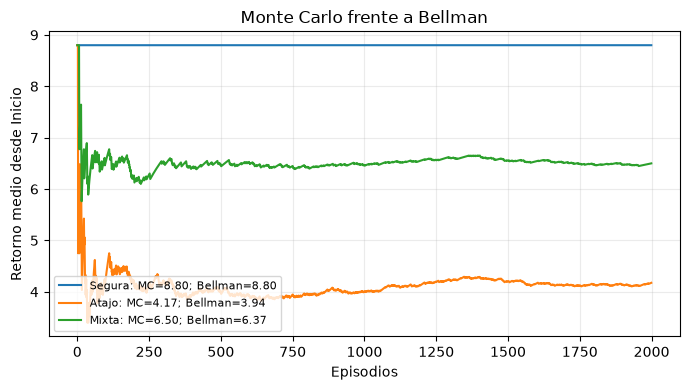

In [14]:
def estimar_valor_mc(politica, n_episodios=2000, descuento=0.9, semilla=100):
    valores = np.empty(n_episodios)
    for i in range(n_episodios):
        trayectoria, _ = ejecutar_episodio(politica, seed=semilla+i)
        valores[i] = retorno_descuento([paso[2] for paso in trayectoria], descuento)
    return valores

fig, ax = plt.subplots(figsize=(7, 4))
for nombre, pi in [("Segura", pi_segura), ("Atajo", pi_atajo), ("Mixta", pi_mixta)]:
    muestras = estimar_valor_mc(pi)
    acumulada = np.cumsum(muestras) / np.arange(1, len(muestras)+1)
    ax.plot(acumulada, label=f"{nombre}: MC={muestras.mean():.2f}; Bellman={evaluar_politica(pi)[INICIO]:.2f}")
    assert abs(muestras.mean()-evaluar_politica(pi)[INICIO]) < 0.4
ax.set(xlabel="Episodios", ylabel="Retorno medio desde Inicio", title="Monte Carlo frente a Bellman")
ax.legend(fontsize=8); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()


# <span style="color:#174ea6">5. Exploración y explotación</span>

Hasta ahora el modelo de transición era conocido. Cuando el agente **desconoce** qué acción funciona mejor, debe decidir entre:

- **Explotación:** usar la mejor acción estimada.
- **Exploración:** probar acciones menos conocidas para mejorar sus estimaciones.

Una regla elemental es la política $\varepsilon$-voraz: con probabilidad $1-\varepsilon$ se elige la acción de mayor valor estimado y con probabilidad $\varepsilon$ una acción al azar. El experimento del bandido multibrazo, desarrollado en el cuaderno original 03, aísla este dilema porque **no incluye transiciones de estado**. Por eso resulta un puente útil, pero no sustituye un MDP.

**Advertencia industrial:** la exploración ingenua puede ser inaceptable cuando hay restricciones de seguridad. El hecho de que una acción sea exploratoria no la vuelve admisible.

In [15]:
def epsilon_voraz(q, epsilon, generador):
    if generador.random() < epsilon:
        return int(generador.integers(len(q)))
    return int(np.argmax(q))

q_est = np.array([2.0, 1.0, 0.5])
g = np.random.default_rng(8)
for epsilon in (0.0, 0.1, 1.0):
    elecciones = np.bincount([epsilon_voraz(q_est, epsilon, g)
                             for _ in range(10000)], minlength=3) / 10000
    print(f"epsilon={epsilon:3.1f}: frecuencia por acción {elecciones.round(3)}")

epsilon=0.0: frecuencia por acción [1. 0. 0.]
epsilon=0.1: frecuencia por acción [0.934 0.031 0.035]
epsilon=1.0: frecuencia por acción [0.333 0.337 0.33 ]



# <span style="color:#174ea6">5A. El bandido de cinco brazos: aprender a elegir cuando no conocemos las probabilidades</span>

En el ejemplo original del **bandido multibrazo** hay cinco máquinas (o cinco brazos de una misma máquina). En cada jugada elegimos **un solo brazo**:

- Si hay éxito, obtenemos recompensa $R=1$.
- Si no hay éxito, obtenemos $R=0$.

Cada brazo tiene una probabilidad fija de éxito. **Nosotros conocemos esas probabilidades porque estamos construyendo el ejemplo; el agente no las conoce.** Debe descubrirlas mediante la experiencia.

Este problema es especialmente sencillo: a diferencia del MDP del ratón, **no necesitamos seguir un estado que cambie después de cada acción**. Solo elegimos, recibimos recompensa y aprendemos.

### 5A.1 Ilustración del bandido

Las probabilidades verdaderas, conservadas exactamente del cuaderno original, son:

| Brazo | 1 | 2 | 3 | 4 | 5 |
|---|---:|---:|---:|---:|---:|
| Probabilidad de éxito | 0.10 | 0.30 | 0.05 | 0.55 | 0.40 |

El **brazo 4** es el mejor, porque su recompensa esperada es $0.55$ por jugada. Pero el agente tendrá que aprenderlo.

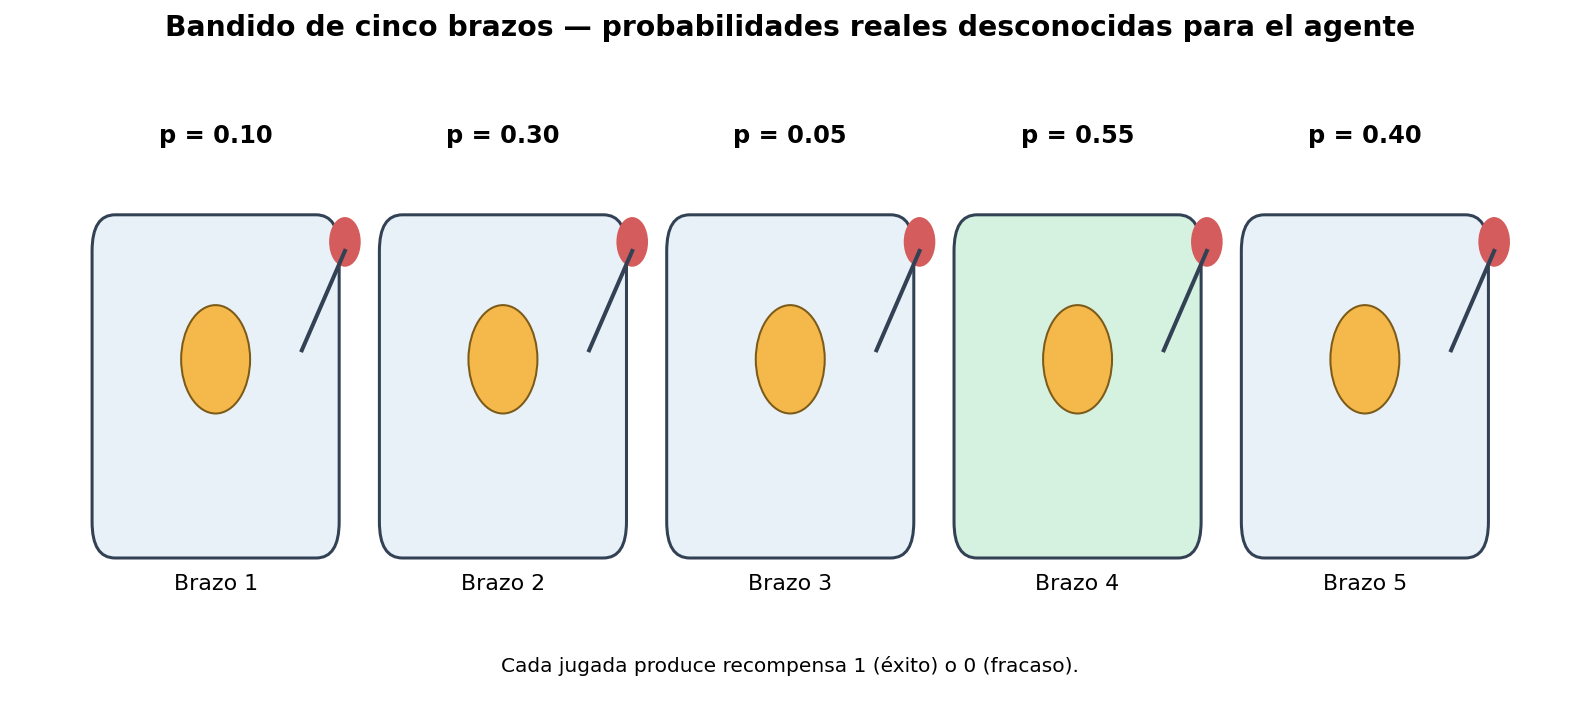

### 5A.2 ¿Cómo aprende el agente? Una cuenta muy pequeña

Supongamos que el brazo 2 ha sido elegido cuatro veces y produjo las recompensas:

$$
1,\quad 0,\quad 1,\quad 0.
$$

Su recompensa promedio observada es:

$$
\widehat Q(2)=\frac{1+0+1+0}{4}=0.5.
$$

Ese $0.5$ es **una estimación**, no la probabilidad verdadera ($0.30$). Con solo cuatro jugadas puede haber bastante error.

Para cualquier brazo $a$, después de haberlo elegido $N(a)$ veces:

$$
\widehat Q(a)=\frac{\text{suma de recompensas obtenidas con }a}{N(a)}.
$$

También podemos actualizar la estimación sin guardar todas las recompensas:

$$
\widehat Q_{\mathrm{nuevo}}(a)
=\widehat Q_{\mathrm{anterior}}(a)
+\frac{R-\widehat Q_{\mathrm{anterior}}(a)}{N(a)}.
$$

**El problema:** si elegimos siempre el brazo que parece mejor en este momento, podríamos quedarnos con una impresión equivocada causada por las primeras jugadas.

### 5A.3 La política $\varepsilon$-greedy, paso a paso

Una política **$\varepsilon$-voraz** (epsilon-greedy) combina dos comportamientos:

1. Con probabilidad $1-\varepsilon$, **explotamos**: elegimos el brazo con mayor recompensa promedio estimada.
2. Con probabilidad $\varepsilon$, **exploramos**: elegimos un brazo al azar, entre los cinco.

En el cuaderno original se usa:

$$
\varepsilon=0.1.
$$

Es decir, en cada jugada:

- Hay un **90 %** de probabilidad de escoger el brazo que actualmente parece mejor.
- Hay un **10 %** de probabilidad de escoger al azar uno de los cinco brazos.

**Detalle importante:** explorar al azar puede seleccionar también el brazo que ya parecía mejor. Por eso, cuando existe un único brazo estimado como mejor, su probabilidad total de selección es $0.9+0.1/5=0.92$; cada uno de los otros cuatro tiene probabilidad $0.1/5=0.02$.

**Ejemplo concreto.** Si las estimaciones son $(0.10,\,0.25,\,0.00,\,0.40,\,0.30)$, el agente explotará el brazo 4, pero ocasionalmente probará los demás. Así puede corregir estimaciones equivocadas.

### 5A.4 Experimento completo: 1000 jugadas

Conservamos los parámetros del ejemplo original:

$$
(p_1,p_2,p_3,p_4,p_5)=(0.10,0.30,0.05,0.55,0.40),
\qquad \varepsilon=0.10,\qquad N=1000.
$$

En cada jugada:

1. Elegimos un brazo usando $\varepsilon$-greedy.
2. Simulamos éxito ($1$) o fracaso ($0$) con la probabilidad verdadera de ese brazo.
3. Actualizamos el número de intentos, la recompensa acumulada y la media observada.
4. Repetimos hasta completar 1000 jugadas.

El resultado exacto cambia entre simulaciones; lo que buscamos es que las estimaciones se aproximen a las probabilidades reales y que el agente seleccione con frecuencia el brazo 4.

Brazo | Prob. real | Intentos | Media estimada
    1 |       0.10 |       26 |          0.154
    2 |       0.30 |       19 |          0.158
    3 |       0.05 |       17 |          0.118
    4 |       0.55 |      626 |          0.535
    5 |       0.40 |      312 |          0.385
Brazo recomendado: 4
Recompensa acumulada: 464 de 1000 jugadas


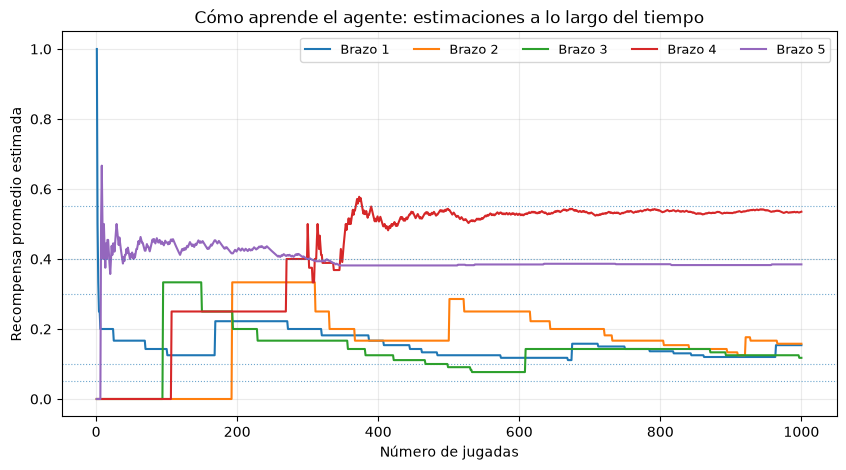

In [20]:
import numpy as np
import matplotlib.pyplot as plt

probabilidades_reales = np.array([0.10, 0.30, 0.05, 0.55, 0.40])
epsilon = 0.10
n_jugadas = 1000
rng_bandido = np.random.default_rng(600)

intentos = np.zeros(5, dtype=int)
recompensas = np.zeros(5, dtype=int)
estimaciones = np.zeros(5, dtype=float)
historial = np.zeros((n_jugadas, 5))
elecciones = np.zeros(n_jugadas, dtype=int)
ganancias = np.zeros(n_jugadas, dtype=int)

for t in range(n_jugadas):
    if rng_bandido.random() < epsilon:   # explorar
        brazo = int(rng_bandido.integers(5))
    else:                                # explotar
        brazo = int(np.argmax(estimaciones))

    premio = int(rng_bandido.random() < probabilidades_reales[brazo])
    intentos[brazo] += 1
    recompensas[brazo] += premio
    estimaciones[brazo] = recompensas[brazo] / intentos[brazo]
    elecciones[t] = brazo
    ganancias[t] = premio
    historial[t] = estimaciones

print("Brazo | Prob. real | Intentos | Media estimada")
for i in range(5):
    print(f"{i+1:5d} | {probabilidades_reales[i]:10.2f} | {intentos[i]:8d} | {estimaciones[i]:14.3f}")
print(f"Brazo recomendado: {np.argmax(estimaciones)+1}")
print(f"Recompensa acumulada: {ganancias.sum()} de {n_jugadas} jugadas")

fig, ax = plt.subplots(figsize=(10, 5))
for i in range(5):
    ax.plot(np.arange(1, n_jugadas+1), historial[:,i], label=f"Brazo {i+1}")
    ax.axhline(probabilidades_reales[i], ls=':', lw=.8, alpha=.65)
ax.set(xlabel="Número de jugadas", ylabel="Recompensa promedio estimada",
       title="Cómo aprende el agente: estimaciones a lo largo del tiempo")
ax.legend(ncol=5, fontsize=9)
ax.grid(alpha=.25)
plt.show()


### 5A.5 ¿Qué sucede si nunca exploramos?

Si usamos $\varepsilon=0$, siempre elegimos el brazo que **parece** mejor. Una recompensa afortunada al principio puede hacernos insistir en un brazo inferior. En cambio, con $\varepsilon=0.1$ seguimos probando alternativas.

**No significa que debamos explorar siempre un 10 %:** es una decisión de diseño. En problemas reales, explorar puede tener costos o riesgos, y es necesario considerar restricciones de seguridad.

### 5A.6 Relación con el MDP y Hydro-Lab

El bandido enseña el dilema **exploración frente a explotación** en su forma más simple. En un MDP, además, las acciones cambian el estado futuro, y las recompensas pueden llegar más tarde. En Hydro-Lab no basta con probar acciones al azar: el agente debe respetar límites operativos y aprender en simulación antes de cualquier uso en un sistema físico.

**Idea para recordar:** el bandido aprende *qué acción suele recompensar más*; un agente de RL en un MDP aprende *qué acción conviene tomar en cada estado*, teniendo en cuenta sus consecuencias futuras.


# <span style="color:#174ea6">6. Estado verdadero, observación y límites del modelo</span>

En un MDP plenamente observable, el agente conoce $S_t$. En muchos sistemas físicos recibe únicamente una observación $O_t$, posiblemente incompleta o ruidosa. En ese caso, la formulación más fiel puede ser un **POMDP** (proceso de decisión de Markov parcialmente observable).

No debemos confundir estas dos afirmaciones:

1. El **estado físico completo** puede satisfacer aproximadamente una hipótesis markoviana.
2. La **observación que recibe el controlador** puede no contener suficiente información para reconstruir ese estado.

En un POMDP, una distribución de creencia $b_t(s)=P(S_t=s\mid O_{0:t},A_{0:t-1})$ puede resumir la incertidumbre sobre el estado. Construir esa creencia es un problema de inferencia, distinto de elegir la acción óptima.

**Pregunta:** ¿cómo cambia la política si el ratón no sabe con certeza si el siguiente pasillo contiene una descarga?


# <span style="color:#174ea6">7. Aplicación a Hydro-Lab: formular el problema antes de entrenar</span>

<img src="../Imagenes/arquitectura_laboratorio_G2.4.png" width="850"/>

*Referencia visual del diseño de Hydro-Lab G2.4. Esta imagen debe existir en `Imagenes/` del repositorio; si allí tiene otro nombre, ajustar únicamente la referencia.*

Hydro-Lab es un **laboratorio sintético** de una red de transporte de hidrocarburos. La formulación utilizada en la línea S2.11 permite analizar decisiones secuenciales sobre tres bombas, bajo variaciones de demanda y condiciones de operación.

| Componente | Correspondencia didáctica en Hydro-Lab |
|---|---|
| Estado físico | Variables hidráulicas y operativas internas de la simulación |
| Observación del agente | Vector numérico de 15 componentes en la interfaz RL S2.11 |
| Acción | Vector continuo normalizado de 3 componentes, uno por bomba, dentro de `[-1,1]` |
| Transición | Evolución simulada de la red después de aplicar el control |
| Recompensa | Evaluación escalar del desempeño de la política, conforme a la implementación |
| Episodio | Hasta 96 intervalos de 15 minutos; puede finalizar antes |
| Política | Regla que transforma observaciones en acciones admisibles |

**Límite de esta lección:** esta tabla es una interpretación pedagógica apoyada en la documentación S2.11, no una especificación exhaustiva de las 15 variables ni de todos los términos de la recompensa. Esas definiciones deben consultarse en el código y el manual del simulador.

**Regla de integridad experimental:** el controlador no debe recibir variables privilegiadas de diagnóstico, por ejemplo `info['evaluation_truth']`, que no forman parte de su observación.

### 7.1 El paso decisivo: ¿qué significa una buena política industrial?

El ratón aprende a evitar descargas y buscar queso. Un controlador de hidrocarburos debe considerar simultáneamente continuidad del servicio, consumo energético, desgaste, límites físicos y condiciones de seguridad.

La analogía tiene límites importantes:

1. **Recompensa no equivale a seguridad.** Una política con retorno alto puede incumplir una restricción dura.
2. **Una observación no siempre es el estado completo.** El control puede requerir memoria, estimación o representación de incertidumbre.
3. **Un resultado promedio no basta.** Debemos evaluar escenarios, semillas y causas de terminación.
4. **Una política aprendida no necesariamente supera a una regla simple.** La comparación con líneas base es indispensable.

En Hydro-Lab S2.11, PPO se estudia precisamente como un método cuya utilidad debe **demostrarse empíricamente**, no presumirse por ser un algoritmo avanzado.

### 7.2 Actividad de cierre: del MDP discreto al control continuo

**Trabajo en parejas (5–8 minutos).** Completen verbalmente la siguiente formulación sin consultar aún el código de PPO:

- ¿Qué información necesita una política para decidir sobre las tres bombas?
- ¿Qué restricciones deben imponerse por fuera de la recompensa?
- ¿Qué consecuencias pueden aparecer varias horas después de una acción?
- ¿Cómo separarían escenarios de entrenamiento y de evaluación?
- ¿Qué comparación demostraría que aprender una política vale la pena?

**Producto esperado:** un diagrama agente–ambiente, una definición de observación, acción y retorno, y al menos dos riesgos de modelado.

**Transición al cuaderno 102:** en este cuaderno **conocíamos** el modelo $P$ y resolvimos Bellman por programación dinámica. En el siguiente aprenderemos a estimar valores a partir de transiciones observadas, primero con Q-learning y después con aproximadores neuronales.


# <span style="color:#174ea6">8. Ejercicios de profundización</span>

**E1 — Bellman a mano.** Para $\gamma=0.9$, calcule $V^\pi(\mathrm{Inicio})$ bajo la política segura y la del atajo. Explique por qué una ruta con menos pasos puede ser peor.

**E2 — Sensibilidad al riesgo.** Cambie la probabilidad de alcanzar el queso desde el atajo. Determine analíticamente el umbral en el que ambas rutas tienen igual valor. Compruebe con código.

**E3 — Sensibilidad al descuento.** Grafique $V^\pi(\mathrm{Inicio})$ para ambas políticas en función de $\gamma\in[0,0.99]$. ¿Cambia la decisión óptima?

**E4 — Recompensa y restricciones.** Formule un caso donde una política tenga mayor retorno esperado, pero sea inaceptable por la probabilidad de una falla grave.

**E5 — Estado y observación.** Proponga una variable oculta de Hydro-Lab que obligaría a ampliar la representación del agente. ¿Cómo comprobaría si la observación actual es suficiente?

**E6 — Diseño experimental.** Explique por qué comparar dos políticas en escenarios diferentes puede inducir conclusiones erróneas.


# <span style="color:#174ea6">9. Comprobaciones automáticas</span>

Estas pruebas detectan errores elementales en el modelo y en los cálculos de la lección. Deben ejecutarse antes de publicar el cuaderno.

In [9]:
assert all(np.isclose(sum(p for p, _, _ in T[s][a]), 1.0)
           for s in range(len(S)) for a in range(len(A)))
assert np.isclose(evaluar_politica(pi_segura)[INICIO], -0.2 + 0.9*10.0)
assert np.isclose(evaluar_politica(pi_atajo)[INICIO], -0.2 + 0.9*(0.7*10-0.3*8))
assert Vopt[INICIO] >= evaluar_politica(pi_segura)[INICIO] - 1e-9
assert Vopt[INICIO] >= evaluar_politica(pi_atajo)[INICIO] - 1e-9
assert np.isclose(Vopt[QUESO], 0) and np.isclose(Vopt[DESCARGA], 0)
print("Todas las comprobaciones del cuaderno 101 pasaron.")

Todas las comprobaciones del cuaderno 101 pasaron.



# <span style="color:#174ea6">10. Fuentes, atribuciones y continuidad editorial</span>

### Cuadernos de la colección original

- **Fuente directa principal:** `01_ar_Aprendizaje_Reforzado_Intro.ipynb`: ratón, interacción agente–ambiente, Markov, retorno, políticas, observabilidad e imágenes históricas.
- **Fuente complementaria:** `02_ar_Agente_simple.ipynb`: anatomía de un agente y ejecución de episodios.
- **Fuente complementaria:** `03_ar_Bandido_Multi_brazo .ipynb`: exploración–explotación y política $\varepsilon$-voraz.
- **Fuente contextual:** `06_r_OpenAI_Gym_Frozen_Lake.ipynb`: entorno discreto y episodios; la implementación se reserva para el cuaderno 102.
- **Contexto industrial:** `Manual_Hydro_Lab_S2.11_G3.1.md` y documentación del laboratorio.

### Bibliografía académica

1. Sutton, R. S. y Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, 2.ª ed. MIT Press. [Edición de los autores](http://incompleteideas.net/book/the-book-2nd.html).
2. Bellman, R. (1957). *Dynamic Programming*. Princeton University Press.
3. Puterman, M. L. (1994). *Markov Decision Processes: Discrete Stochastic Dynamic Programming*. Wiley.
4. Gymnasium, documentación de referencia de entornos y API: https://gymnasium.farama.org/

### Atribuciones de recursos visuales

Se reutilizan las rutas relativas de imágenes de la colección original. Las atribuciones de imágenes de terceros se conservan junto a las figuras y deben verificarse antes de redistribuir archivos en un repositorio público.

**Nota de integridad editorial:** la implementación Python del MDP del ratón y sus pruebas es nueva para esta edición. No modifica ni sobrescribe los cuadernos fuente. Las figuras solo se referencian; sus archivos no se incrustan ni se copian en este `.ipynb`.

---

**Siguiente cuaderno:** `102_ar_Q_Learning_DQN.ipynb` — aprender valores a partir de experiencia.
